<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Neural Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<ul style="list-style:none;padding-left:0;margin:0">
  <li><a href="01_Einleitung.ipynb">1. Einleitung</a></li>
  <li><a href="02_Datenerzeugung.ipynb">2. Datenerzeugung</a></li>
  <li><a href="03_ESN_Baseline_Clean.ipynb">3. ESN-Baseline</a></li>
  <li><strong>4. Robustheit gegenüber Rauschen</strong></li>
  <li><a href="05_Out_of_Distribution.ipynb">5. Out-of-Distribution-Analyse</a></li>
  <li><a href="06_Schluss.ipynb">6. Schlussfolgerung</a></li>
</ul>

---

# 4. Robustheit gegenüber Rauschen

In der Praxis sind Messdaten selten rauschfrei. Sensoren, Digitalisierungsfehler und Übertragungsstörungen überlagern das wahre Signal mit zufälligem Rauschen. Dieses Kapitel untersucht, wie empfindlich das Baseline-Modell und das optimierte Modell aus Notebook 3 auf solches Rauschen reagieren.

Dazu wird der Eingang des ESN mit additivem Gauss'schem Rauschen verunreinigt und der NRMSE gegenüber dem sauberen Zielwert gemessen. Das Ziel ist, den kritischen Rauschpegel zu identifizieren, ab dem die Vorhersagegüte merklich abnimmt, und die beiden Modelle hinsichtlich ihrer Robustheit zu vergleichen.

## 4.1. Imports und Grundeinstellungen

In [59]:
import os

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt

from utils import esn_utils as eu
from utils import plot_utils as pu

eu.set_seed(42)

DEVICE  = eu.DEVICE
SEED    = 42
WARMUP  = 100
N_MC    = 10

print(f"Device: {DEVICE}")

Device: cpu


## 4.2. Modelle laden

Für den Vergleich werden zwei Modelle aus Notebook 3 verwendet:

| Modell | Reservoir N | Spektralradius SR | NRMSE (sauber) |
|---|---|---|---|
| Baseline | 300 | 0.95 | 0.0024 |
| Optimiert | 400 | 0.98 | 0.0016 |

Das **optimierte Modell** wird direkt aus dem in Notebook 3 gespeicherten Checkpoint geladen. Die **Baseline** wird hier neu trainiert, mit denselben Hyperparametern und demselben Seed wie in Notebook 3, sodass die Reproduzierbarkeit gewährleistet ist.

In [60]:
train_data = np.load("data/train_clean.npy", allow_pickle=True)
test_data  = np.load("data/test_clean_id.npy", allow_pickle=True)

eu.validate_oscillation_dataset(train_data, "Trainingsdaten")
eu.validate_oscillation_dataset(test_data,  "Testdaten")

train_dataset = eu.OscillationSequenceDataset(train_data)
test_dataset  = eu.OscillationSequenceDataset(test_data)

Trainingsdaten: Struktur OK, 25 Schwingungen
Testdaten: Struktur OK, 25 Schwingungen


### 4.2.1. Optimiertes Modell aus Checkpoint laden

In [61]:
ckpt = torch.load("models/esn_baseline_best.pt", map_location=DEVICE, weights_only=False)
cfg  = ckpt["config"]

model_opt = eu.EchoStateNetwork(
    n_reservoir     = cfg["best_n_reservoir"],
    spectral_radius = cfg["best_spectral_radius"],
    sparsity        = cfg["sparsity"],
    input_scaling   = cfg["input_scaling"],
    leaking_rate    = cfg["leaking_rate"],
    seed            = cfg["final_seed"],
    verbose         = False,
).to(DEVICE)
model_opt.load_state_dict(ckpt["model_state_dict"])
model_opt.eval()

NRMSE_OPT_CLEAN = float(cfg["mean_nrmse_id"])
print(
    f"Optimiertes Modell: N={cfg['best_n_reservoir']}, SR={cfg['best_spectral_radius']}, "
    f"Seed={cfg['final_seed']}\n"
    f"NRMSE (sauber, aus NB3): {NRMSE_OPT_CLEAN:.4f}"
)

Optimiertes Modell: N=400, SR=0.98, Seed=67
NRMSE (sauber, aus NB3): 0.0016


### 4.2.2. Baseline neu trainieren (N=300, SR=0.95)

In [62]:
eu.set_seed(SEED)

model_baseline = eu.EchoStateNetwork(
    n_reservoir     = 300,
    spectral_radius = 0.95,
    sparsity        = 0.1,
    input_scaling   = 1.0,
    leaking_rate    = 1.0,
    seed            = SEED,
    verbose         = False,
).to(DEVICE)

X_train, y_train = eu.collect_states(model_baseline, train_dataset, warmup=WARMUP, device=DEVICE)
X_test,  y_test  = eu.collect_states(model_baseline, test_dataset,  warmup=WARMUP, device=DEVICE)

eu.train_readout(
    model_baseline, X_train, y_train, X_test, y_test,
    n_epochs=100, lr=1e-3, batch_size=256, device=DEVICE, print_every=25,
)

nrmse_df_baseline    = eu.evaluate_model(model_baseline, test_data, warmup=WARMUP, device=DEVICE)
NRMSE_BASELINE_CLEAN = float(nrmse_df_baseline["nrmse"].mean())
print(f"\nBaseline: N=300, SR=0.95, NRMSE (sauber): {NRMSE_BASELINE_CLEAN:.4f}")

Epoche   1/100 | Train-NRMSE=0.193922 | Test-NRMSE=0.017348
Epoche  25/100 | Train-NRMSE=0.004221 | Test-NRMSE=0.003576
Epoche  50/100 | Train-NRMSE=0.002183 | Test-NRMSE=0.002592
Epoche  75/100 | Train-NRMSE=0.001474 | Test-NRMSE=0.001900
Epoche 100/100 | Train-NRMSE=0.001193 | Test-NRMSE=0.001908

Baseline: N=300, SR=0.95, NRMSE (sauber): 0.0024


## 4.3. Rauschmodell: Additives Gauss'sches Rauschen

Untersucht wird der Einfluss von additivem weissem Gauss'schem Rauschen (AWGN) auf die Vorhersagegüte. Das Rauschmodell lautet:

$$\tilde{y}(t) = y(t) + \varepsilon(t), \qquad \varepsilon(t) \sim \mathcal{N}(0,\, \sigma^2)$$

wobei $y(t)$ das saubere Signal und $\sigma$ die Standardabweichung des Rauschens ist. Das verrauschte Signal $\tilde{y}(t)$ simuliert Messungenauigkeiten, wie sie in realen Sensorsystemen auftreten. Die Rauschterme $\varepsilon(t)$ sind zu verschiedenen Zeitpunkten stochastisch unabhängig und normalverteilt, was dem klassischen AWGN-Modell entspricht, das in der Signalverarbeitung weit verbreitet ist [Proakis & Salehi, 2008].

**Relativer Rauschpegel:** Die absolute Rauschstärke $\sigma$ hängt von der Signalamplitude ab. Da die Trainingsdaten verschiedene Amplituden $A \in [0.5, 2.0]$ abdecken, wird $\sigma$ relativ zum Wertebereich der jeweiligen Sequenz normiert:

$$\sigma_{\text{rel}} = \frac{\sigma}{\max(y) - \min(y)}$$

Diese Normierung ist konsistent mit dem NRMSE, der ebenfalls auf den Wertebereich bezogen ist. Ein Wert von $\sigma_{\text{rel}} = 0.01$ bedeutet, dass die Rauschstandardabweichung 1 % des Signalbereichs beträgt.

**Eingabe und Zielwert:** Das verrauschte Signal $\tilde{y}(t)$ dient als Eingang für das ESN. Verglichen wird die Vorhersage $\hat{y}(t+1)$ jedoch mit dem **sauberen Zielwert** $y(t+1)$, da das Modell in der Praxis das wahre Signal schätzen soll. Der gemessene NRMSE beinhaltet daher sowohl die Modellunsicherheit als auch den Fehler, der durch das verrauschte Eingangssignal entsteht.

**Monte-Carlo-Averaging:** Da das Rauschen stochastisch ist, liefert jede Rauschrealisierung leicht unterschiedliche NRMSE-Werte. Eine einzelne Realisierung könnte zufällig besonders günstig oder ungünstig ausfallen und wäre damit kein verlässlicher Schätzer für die erwartete Leistung des Modells unter Rauschen.

Das Monte-Carlo-Verfahren löst dieses Problem durch wiederholte unabhängige Stichproben: Für jeden Rauschpegel werden $N_{\text{MC}} = 10$ unabhängige Rauschsequenzen gezogen und der NRMSE für jede Realisierung berechnet. Der Schätzer für den erwarteten NRMSE ist dann der Stichprobenmittelwert:

$$\widehat{\text{NRMSE}}(\sigma_{\text{rel}}) = \frac{1}{N_{\text{MC}}} \sum_{i=1}^{N_{\text{MC}}} \text{NRMSE}_i$$

Nach dem Gesetz der grossen Zahlen und dem zentralen Grenzwertsatz konvergiert dieser Schätzer mit wachsendem $N_{\text{MC}}$ gegen den wahren Erwartungswert [Proakis & Salehi, 2008]. Die Standardabweichung über die $N_{\text{MC}}$ Läufe misst die Schätzunsicherheit und bildet das Konfidenzband in den Plots.

## 4.4. Robustheit gegenüber Rauschen

### 4.4.1. Rauschlevels definieren

Zwölf Rauschpegel werden getestet, von sauberem Input ($\sigma_{\text{rel}} = 0$) bis zu starkem Rauschen ($\sigma_{\text{rel}} = 0.1$, d.h. die Rauschstandardabweichung entspricht 10 % des Signalbereichs). Die Abstufung ist fein gewählt, um den Übergangsbereich gut aufzulösen, in dem die Vorhersagequalität merklich abnimmt.

In [63]:
SIGMA_RELS = [0.0, 0.001, 0.002, 0.003, 0.005, 0.007, 0.01, 0.02, 0.03, 0.05, 0.07, 0.1]

print("Getestete relative Rauschpegel σ_rel:")
for s in SIGMA_RELS:
    print(f"  σ_rel = {s:.3f}")

Getestete relative Rauschpegel σ_rel:
  σ_rel = 0.000
  σ_rel = 0.001
  σ_rel = 0.002
  σ_rel = 0.003
  σ_rel = 0.005
  σ_rel = 0.007
  σ_rel = 0.010
  σ_rel = 0.020
  σ_rel = 0.030
  σ_rel = 0.050
  σ_rel = 0.070
  σ_rel = 0.100


### 4.4.2. NRMSE-Sweep über Rauschlevels

Für jeden der zwölf Rauschpegel werden $N_{\text{MC}} = 10$ Rauschrealisierungen berechnet. Der NRMSE wird pro Realisierung über alle 25 Testsequenzen gemittelt und anschliessend über die $N_{\text{MC}}$ Läufe gemittelt. Das Konfidenzband (± 1 Std.) gibt die Streuung zwischen den Rauschrealisierungen an.

In [64]:
results_baseline = []
results_opt      = []

for sigma_rel in SIGMA_RELS:
    res_b = eu.evaluate_model_noisy(
        model_baseline, test_data, sigma_rel=sigma_rel,
        n_mc=N_MC, warmup=WARMUP, seed=SEED, device=DEVICE,
    )
    res_o = eu.evaluate_model_noisy(
        model_opt, test_data, sigma_rel=sigma_rel,
        n_mc=N_MC, warmup=WARMUP, seed=SEED, device=DEVICE,
    )
    results_baseline.append(res_b)
    results_opt.append(res_o)
    print(
        f"σ_rel={sigma_rel:.3f} | "
        f"Baseline: {res_b['mean']:.4f} ± {res_b['std']:.5f} | "
        f"Opt:      {res_o['mean']:.4f} ± {res_o['std']:.5f}"
    )

σ_rel=0.000 | Baseline: 0.0024 ± 0.00000 | Opt:      0.0016 ± 0.00000
σ_rel=0.001 | Baseline: 0.0050 ± 0.00003 | Opt:      0.0050 ± 0.00004
σ_rel=0.002 | Baseline: 0.0090 ± 0.00007 | Opt:      0.0097 ± 0.00008
σ_rel=0.003 | Baseline: 0.0132 ± 0.00011 | Opt:      0.0143 ± 0.00012
σ_rel=0.005 | Baseline: 0.0216 ± 0.00019 | Opt:      0.0238 ± 0.00020
σ_rel=0.007 | Baseline: 0.0302 ± 0.00026 | Opt:      0.0333 ± 0.00028
σ_rel=0.010 | Baseline: 0.0430 ± 0.00037 | Opt:      0.0475 ± 0.00040
σ_rel=0.020 | Baseline: 0.0857 ± 0.00074 | Opt:      0.0946 ± 0.00079
σ_rel=0.030 | Baseline: 0.1280 ± 0.00109 | Opt:      0.1414 ± 0.00117
σ_rel=0.050 | Baseline: 0.2109 ± 0.00176 | Opt:      0.2328 ± 0.00189
σ_rel=0.070 | Baseline: 0.2906 ± 0.00236 | Opt:      0.3206 ± 0.00254
σ_rel=0.100 | Baseline: 0.4031 ± 0.00314 | Opt:      0.4443 ± 0.00339


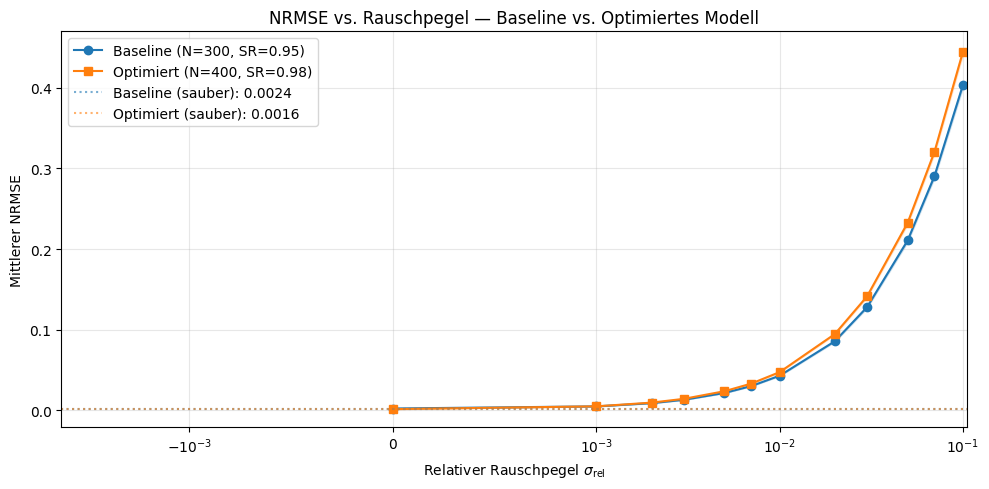

In [65]:
pu.plot_nrmse_vs_noise(
    sigma_levels     = SIGMA_RELS,
    results_baseline = results_baseline,
    results_opt      = results_opt,
    ref_baseline     = NRMSE_BASELINE_CLEAN,
    ref_opt          = NRMSE_OPT_CLEAN,
)

**Beobachtung:**

Der NRMSE steigt nahezu linear mit dem Rauschpegel an. Bereits bei $\sigma_{\text{rel}} = 0.001$ liegen beide Modelle bei NRMSE $\approx 0.005$: Der Vorteil des optimierten Modells (NRMSE = 0.0016 auf sauberen Daten gegenüber 0.0024 der Baseline) ist damit vollständig verschwunden.

Ab $\sigma_{\text{rel}} \approx 0.001$ liegt die Baseline bei allen getesteten Rauschpegeln unterhalb des optimierten Modells. Bei $\sigma_{\text{rel}} = 0.1$ beträgt der Unterschied NRMSE 0.403 (Baseline) gegenüber 0.444 (optimiert), was einer Differenz von rund 10 % entspricht.

Das grössere Reservoir (N = 400) gewichtet den verrauschten Eingang stärker als das kleinere Reservoir (N = 300). Dadurch wirkt sich das Rauschen auf die Reservoirzustände des optimierten Modells stärker aus, was den Leistungsvorteil bei sauberem Signal unter Rauschen überkompensiert.

Die Konfidenzb­änder (±1 Std. über die $N_{\text{MC}} = 10$ Rauschrealisierungen) sind im Plot als sehr schmale Bereiche um die Kurven sichtbar. Die relative Standardabweichung beträgt weniger als 1 % des jeweiligen NRMSE-Werts (z.B. Std. = 0.003 bei NRMSE = 0.403). Das bedeutet: Das Ergebnis hängt kaum von der konkreten Rauschrealisierung ab, und $N_{\text{MC}} = 10$ Läufe reichen für eine stabile Schätzung aus.

### 4.4.3. Lineare Regression des Performanceverlusts

**Warum linear?** Das ESN ist ein stabiles dynamisches System mit Spektralradius $< 1$. Kleine Störungen am Eingang akkumulieren sich deshalb nicht, sondern bleiben proportional zur Rauschstärke und klingen ab. Da der Vorhersagefehler direkt von der Störung des Reservoir-Zustands abhängt, ergibt sich ein linearer Zusammenhang zwischen Rauschpegel und NRMSE. Die Daten bestätigen dies empirisch mit $R^2 > 0.999$.

Das Regressionsmodell lautet:

$$\widehat{\text{NRMSE}}(\sigma_{\text{rel}}) = a + b \cdot \sigma_{\text{rel}}$$

Die Steigung $b$ quantifiziert die **Rauschempfindlichkeit**: wie stark der NRMSE pro Einheit $\sigma_{\text{rel}}$ zunimmt. Der Achsenabschnitt $a$ entspricht näherungsweise dem NRMSE auf sauberen Daten.

**Statistische Tests:** Zusätzliche Tests (t-Test, F-Test) sind nicht nötig. Die Frage ist nicht, ob ein Zusammenhang besteht, sondern wie stark er ist. Dafür liefert $R^2$ das entscheidende Mass: Werte nahe 1 bestätigen das lineare Modell vollständig. Der Unterschied in den Steigungen ist direkt interpretierbar und benötigt keine Signifikanzprüfung.

In [66]:
sigma_arr = np.array(SIGMA_RELS)
nrmse_b_arr = np.array([r["mean"] for r in results_baseline])
nrmse_o_arr = np.array([r["mean"] for r in results_opt])

# Lineare Regression: NRMSE = a + b * sigma_rel
coeffs_b = np.polyfit(sigma_arr, nrmse_b_arr, 1)   # [slope, intercept]
coeffs_o = np.polyfit(sigma_arr, nrmse_o_arr, 1)

slope_b, intercept_b = coeffs_b
slope_o, intercept_o = coeffs_o

def r_squared(y, y_pred):
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1.0 - ss_res / ss_tot

r2_b = r_squared(nrmse_b_arr, intercept_b + slope_b * sigma_arr)
r2_o = r_squared(nrmse_o_arr, intercept_o + slope_o * sigma_arr)

print("Lineare Regression:  NRMSE = a + b · σ_rel")
print(f"\nBaseline:  NRMSE = {intercept_b:.4f} + {slope_b:.3f} · σ_rel   R² = {r2_b:.5f}")
print(f"Optimiert: NRMSE = {intercept_o:.4f} + {slope_o:.3f} · σ_rel   R² = {r2_o:.5f}")
print("\nRauschempfindlichkeit (Steigung b):")
print(f"  Baseline:  {slope_b:.3f} NRMSE-Einheiten pro σ_rel-Einheit")
print(f"  Optimiert: {slope_o:.3f} NRMSE-Einheiten pro σ_rel-Einheit")
print(f"  Das optimierte Modell ist {(slope_o / slope_b - 1) * 100:.1f} % rauschempfindlicher.")

Lineare Regression:  NRMSE = a + b · σ_rel

Baseline:  NRMSE = 0.0026 + 4.065 · σ_rel   R² = 0.99948
Optimiert: NRMSE = 0.0026 + 4.487 · σ_rel   R² = 0.99942

Rauschempfindlichkeit (Steigung b):
  Baseline:  4.065 NRMSE-Einheiten pro σ_rel-Einheit
  Optimiert: 4.487 NRMSE-Einheiten pro σ_rel-Einheit
  Das optimierte Modell ist 10.4 % rauschempfindlicher.


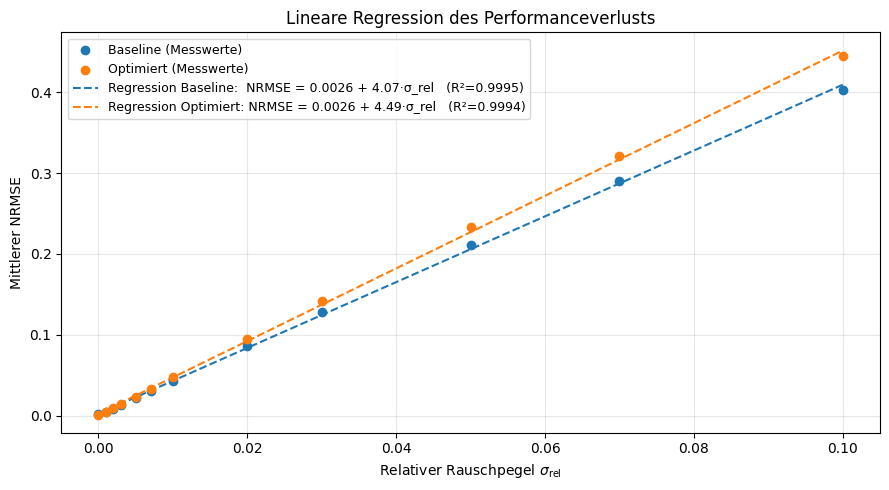

In [67]:
sigma_fit = np.linspace(0, max(SIGMA_RELS), 300)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(sigma_arr, nrmse_b_arr, color="tab:blue",   zorder=5, label="Baseline (Messwerte)")
ax.scatter(sigma_arr, nrmse_o_arr, color="tab:orange", zorder=5, label="Optimiert (Messwerte)")

ax.plot(
    sigma_fit, intercept_b + slope_b * sigma_fit, "--", color="tab:blue",
    label=f"Regression Baseline:  NRMSE = {intercept_b:.4f} + {slope_b:.2f}·σ_rel   (R²={r2_b:.4f})",
)
ax.plot(
    sigma_fit, intercept_o + slope_o * sigma_fit, "--", color="tab:orange",
    label=f"Regression Optimiert: NRMSE = {intercept_o:.4f} + {slope_o:.2f}·σ_rel   (R²={r2_o:.4f})",
)

ax.set_xlabel(r"Relativer Rauschpegel $\sigma_{\mathrm{rel}}$")
ax.set_ylabel("Mittlerer NRMSE")
ax.set_title("Lineare Regression des Performanceverlusts")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Beobachtung:**

Beide Modelle zeigen eine nahezu perfekte lineare Beziehung ($R^2 > 0.9994$). Die Steigungen quantifizieren die Rauschempfindlichkeit direkt: Pro Einheit $\sigma_{\text{rel}}$ steigt der NRMSE der Baseline um $b \approx 4.07$ und der des optimierten Modells um $b \approx 4.49$, was einer Mehrsensitivität von rund 10 % entspricht.

Der Achsenabschnitt $a \approx 0.003$ liegt für beide Modelle leicht über dem tatsächlichen NRMSE auf sauberen Daten (0.0024 bzw. 0.0016). Das ist ein gewöhnliches Verhalten linearer Fits bei Daten mit einem Offset: Bei sehr kleinen $\sigma_{\text{rel}}$ dominiert der Achsenabschnitt, und die lokale Steigung ist etwas niedriger als die global gefittete Gerade. Insgesamt beschreibt das Regressionsmodell die Daten über den gesamten getesteten Bereich sehr gut.

### 4.4.4. Beispielvorhersagen bei ausgewählten Rauschpegeln

Vorhersagen bei drei ausgewählten Rauschpegeln ($\sigma_{\text{rel}} \in \{0.01,\; 0.05,\; 0.1\}$) für das Baseline-Modell und das optimierte Modell. Jedes Teilbild zeigt den sauberen Zielwert (blau), das verrauschte Eingangssignal (grau) und die ESN-Vorhersage (orange) nach der Warmup-Phase von 100 Zeitschritten. Sequenz 0 dient als repräsentatives Beispiel.

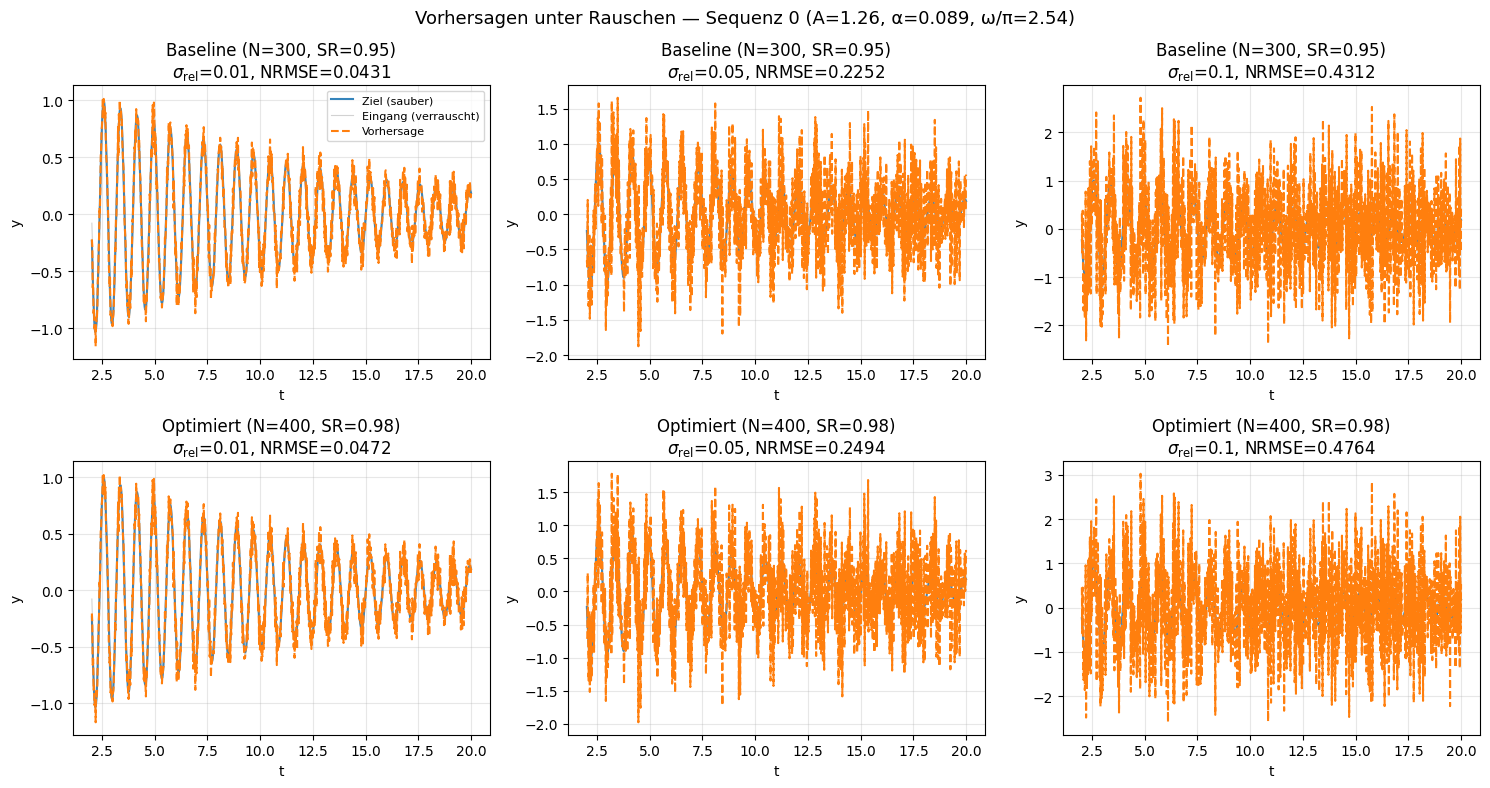

In [68]:
pu.plot_noisy_predictions(
    models     = {"Baseline (N=300, SR=0.95)": model_baseline, "Optimiert (N=400, SR=0.98)": model_opt},
    data       = test_data,
    sigma_rels = [0.01, 0.05, 0.1],
    warmup     = WARMUP,
    seed       = SEED,
    device     = DEVICE,
)

**Beobachtung:**

Bei geringem Rauschen ($\sigma_{\text{rel}} = 0.01$) folgt die Vorhersage dem sauberen Zielwert noch sehr eng. Das verrauschte Eingangssignal ist deutlich sichtbar, beeinflusst die Vorhersage aber kaum. Das Reservoir akkumuliert die Eingabe über mehrere Zeitschritte, was hochfrequente Rauschspitzen teilweise herausmittelt.

Bei mittlerem Rauschen ($\sigma_{\text{rel}} = 0.05$) ist die Abweichung der Vorhersage vom Zielwert gut sichtbar. Die Vorhersage folgt dem Signalverlauf grob, weicht aber phasen- und amplitudenmässig ab.

Bei starkem Rauschen ($\sigma_{\text{rel}} = 0.1$) dominiert das Rauschen das Eingangssignal. Die Vorhersage verliert den Zusammenhang mit dem sauberen Zielwert weitgehend. Beide Modelle zeigen qualitativ ähnliches Verhalten; der Unterschied zwischen Baseline-Modell und optimiertem Modell ist auf dieser Sequenz kaum erkennbar.

### 4.4.5. NRMSE-Verteilung bei ausgewählten Rauschpegeln

Vergleich der sequenzweisen NRMSE-Verteilung über alle 25 Testsequenzen bei sauberem Input ($\sigma_{\text{rel}} = 0$), mittlerem Rauschen ($\sigma_{\text{rel}} = 0.05$) und starkem Rauschen ($\sigma_{\text{rel}} = 0.1$) für das Baseline-Modell und das optimierte Modell. Die Balken zeigen den NRMSE für jede einzelne Testsequenz.

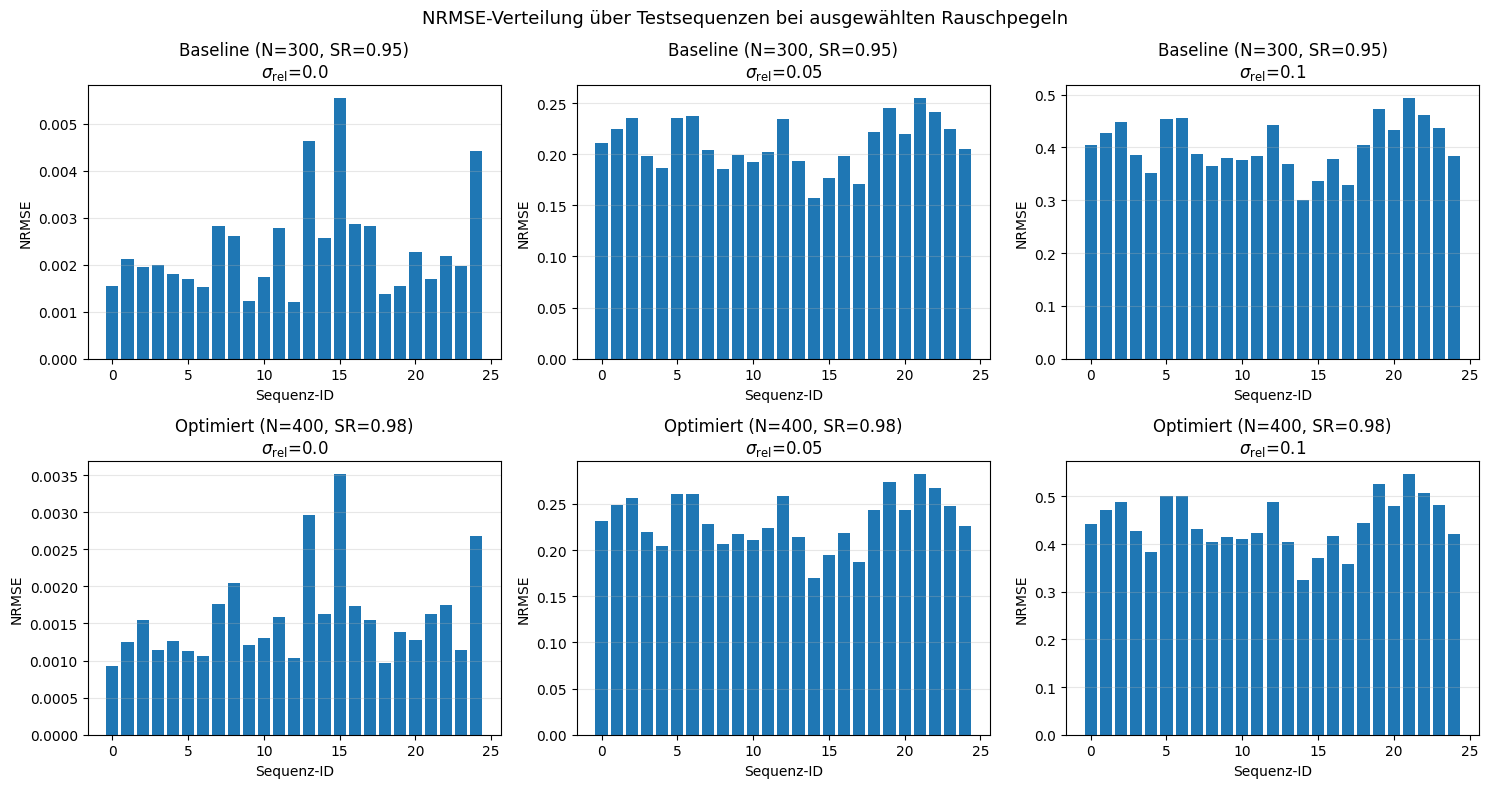

In [69]:
pu.plot_nrmse_distribution_noisy(
    models     = {"Baseline (N=300, SR=0.95)": model_baseline, "Optimiert (N=400, SR=0.98)": model_opt},
    data       = test_data,
    sigma_rels = [0.0, 0.05, 0.1],
    warmup     = WARMUP,
    seed       = SEED,
    device     = DEVICE,
)

**Beobachtung:**

Bei sauberem Input ($\sigma_{\text{rel}} = 0$) streuen die NRMSE-Werte der einzelnen Sequenzen deutlich: Einige Sequenzen werden sehr gut vorhergesagt (NRMSE unter 0.001), andere schlechter (bis etwa 0.004). Diese Streuung reflektiert Unterschiede in den Schwingungsparametern.

Bei zunehmendem Rauschen gleichen sich die NRMSE-Werte der Sequenzen an. Bei $\sigma_{\text{rel}} = 0.1$ liegen fast alle Balken auf ähnlichem Niveau. Das Rauschen dominiert den Fehler unabhängig vom jeweiligen Signal: Es wirkt als Ausgleichsmechanismus, der die Unterschiede zwischen den Sequenzen einebnet.

Die relative Rangordnung der Modelle (Baseline besser als optimiert) bleibt über alle Sequenzen erhalten, ist bei hohem Rauschen aber weniger ausgeprägt.

Die drei Sequenzen, die aufgrund der zu langsamen Dynamik des Modelles aufgefallen sind, verlieren ihre Auffälligkeit mit zunehmendem Rauschen.

## 4.5. Ergebnisse speichern

In [70]:
rows = []
for sigma_rel, res_b, res_o in zip(SIGMA_RELS, results_baseline, results_opt):
    rows.append({
        "sigma_rel":           sigma_rel,
        "baseline_mean_nrmse": res_b["mean"],
        "baseline_std_nrmse":  res_b["std"],
        "opt_mean_nrmse":      res_o["mean"],
        "opt_std_nrmse":       res_o["std"],
    })

noise_results_df = pd.DataFrame(rows)
os.makedirs("results", exist_ok=True)
noise_results_df.to_csv("results/noise_robustness.csv", index=False)
print(noise_results_df.to_string(index=False))

 sigma_rel  baseline_mean_nrmse  baseline_std_nrmse  opt_mean_nrmse  opt_std_nrmse
     0.000             0.002358            0.000000        0.001578   2.168404e-19
     0.001             0.005004            0.000035        0.005047   4.008779e-05
     0.002             0.008988            0.000074        0.009652   8.110813e-05
     0.003             0.013162            0.000112        0.014348   1.215391e-04
     0.005             0.021649            0.000187        0.023797   2.019092e-04
     0.007             0.030191            0.000262        0.033265   2.819267e-04
     0.010             0.043026            0.000373        0.047468   4.013690e-04
     0.020             0.085720            0.000739        0.094650   7.933751e-04
     0.030             0.128041            0.001095        0.141390   1.173502e-03
     0.050             0.210878            0.001761        0.232812   1.889897e-03
     0.070             0.290561            0.002361        0.320635   2.539552e-03
    

## 4.6. Fazit

Das Experiment zeigt drei zentrale Befunde:

**1. Lineares Ansteigen des NRMSE:** Der NRMSE steigt nahezu linear mit dem relativen Rauschpegel an. Zwischen $\sigma_{\text{rel}} = 0$ und $\sigma_{\text{rel}} = 0.1$ wächst der NRMSE der Baseline von 0.0024 auf 0.403, der des optimierten Modells von 0.0016 auf 0.444. Das entspricht einer Steigung von etwa 4.0 (Baseline) bzw. 4.4 (optimiertes Modell) NRMSE-Einheiten pro Einheit $\sigma_{\text{rel}}$.

**2. Schneller Verlust des Leistungsvorteils:** Das optimierte Modell ist auf sauberen Daten 33 % besser als die Baseline (NRMSE 0.0016 gegenüber 0.0024). Dieser Vorteil verschwindet bereits bei $\sigma_{\text{rel}} \approx 0.001$, wo beide Modelle einen NRMSE von 0.005 erreichen. Ab diesem Punkt ist die Baseline bei allen getesteten Rauschpegeln besser.

**3. Grösseres Reservoir ist rauschempfindlicher:** Das optimierte Modell (N = 400) zeigt eine etwas stärkere Rauschempfindlichkeit als die Baseline (N = 300). Ein grösseres Reservoir gewichtet den verrauschten Eingang stärker, da der Eingabevektor $W_{\text{in}}$ mehr Neuronen ansteuert. Dadurch wird das Rauschen im Reservoir stärker amplifiziert, was den Vorteil des grösseren Gedächtnisses unter Rauschen überkompensiert.

**Praktische Einordnung:** Für rauschfreie oder sehr rauscharme Signale ($\sigma_{\text{rel}} < 0.001$) ist das optimierte Modell vorzuziehen. Bei Messrauschen ab $\sigma_{\text{rel}} \approx 0.001$ ist die Baseline robuster. In realen Anwendungen sollte daher der erwartete Rauschpegel bei der Modellwahl berücksichtigt werden.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="03_ESN_Baseline_Clean.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="05_Out_of_Distribution.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>